# RCC

In [2]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

from src import config, eda, utils, pipeline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

In [3]:
from src.features_rcc import detect_schema, _family_map

sample = utils.sample_rows(utils.raw_file("rcc_train"))
productos = utils.load_raw("productos", required=False)
y = utils.load_target()
schema = detect_schema(sample)
print(sample.shape)
schema

(2000000, 9)


{'key': 'key_value',
 'period': 'codmes',
 'amount': 'saldo',
 'institution': 'cod_instit_financiera',
 'product': 'producto',
 'clasif': 'cod_clasificacion_deudor',
 'mora': 'condicion',
 'extra_dims': ['tipo_credito', 'riesgo_directo'],
 'extra_measures': []}

In [4]:
eda.overview(sample, 'rcc_train (muestra)')

rcc_train (muestra): 2,000,000 filas x 9 columnas


,dtype,nulos_%,unicos,ejemplo
codmes,int64,0.0,11,201711.000000
key_value,int64,0.0,93323,4.000000
condicion,int64,0.0,4342,0.000000
tipo_credito,int64,0.0,8,12.000000
cod_instit_financiera,int64,0.0,103,33.000000
saldo,float64,0.0,64013,-0.072601
producto,int64,0.0,38,6.000000
riesgo_directo,int64,0.0,5,-1.000000
cod_clasificacion_deudor,int64,0.0,6,0.000000


## Nulos y distribuciones

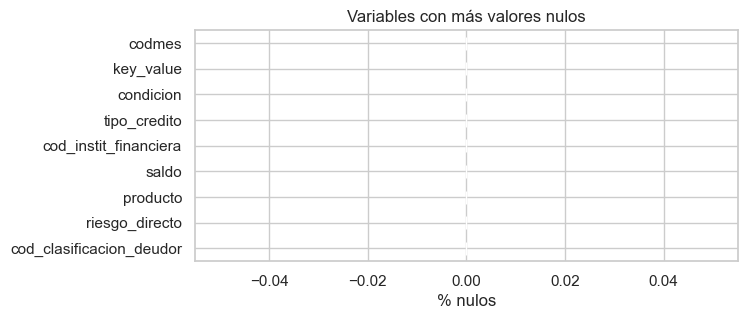

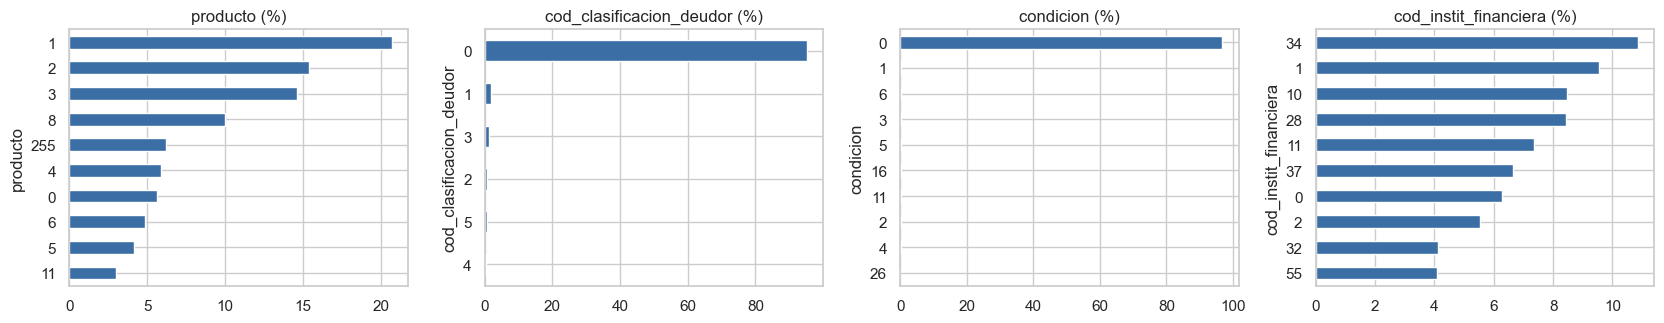

count    2000000.000
mean          -0.002
std            0.520
min           -0.073
50%           -0.064
90%            0.061
99%            0.823
max          100.703
Name: saldo, dtype: float64

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
eda.missing_plot(sample, ax=ax)
plt.show()

dims = [c for c in [schema["product"], schema["clasif"], schema["mora"], schema["institution"]] if c]
fig, axes = plt.subplots(1, len(dims), figsize=(4.2 * len(dims), 3.4))
for ax, c in zip(np.atleast_1d(axes), dims):
    sample[c].astype(str).value_counts(normalize=True).head(10).mul(100)[::-1].plot.barh(ax=ax, color="#3b6ea5")
    ax.set_title(f"{c} (%)")
plt.tight_layout()
plt.show()
sample[schema["amount"]].describe(percentiles=[.5, .9, .99]).round(3)

## Productos

In [6]:
fmap = _family_map(sample, schema["product"], productos)
fam = pd.Series(fmap, name="familia").rename_axis("producto").reset_index()
fam.groupby("familia").producto.apply(lambda s: ", ".join(map(str, s[:8]))).to_frame("productos")

,productos
familia,
consumo,"0, 21, 30"
contable,"6, 1, 9, 29, 32"
empresarial,"4, 23, 24, 34, 36"
garantia,"5, 10, 15, 16"
hipotecario,"19, 22, 38"
linea_no_utilizada,"7, 3, 20, 33"
linea_total_tc,2
otros,255
problema,"12, 17, 25"


## Construcción de variables

In [7]:
del sample
pipeline.run_rcc()
X = utils.load_frame("features_rcc_train")
print(X.shape)
X.head()

23:50:03 | INFO | RCC rcc_train.csv: 30,391,626 filas leídas · 27,140,446 dentro de la ventana · 3,251,180 del mes de desembolso o posteriores descartadas
23:50:04 | INFO | RCC esquema detectado: {'key': 'key_value', 'period': 'codmes', 'amount': 'saldo', 'institution': 'cod_instit_financiera', 'product': 'producto', 'clasif': 'cod_clasificacion_deudor', 'mora': 'condicion', 'extra_dims': ['tipo_credito', 'riesgo_directo']}
23:50:04 | INFO | RCC: monto estandarizado; se desplaza en 0.072892 para recuperar una escala no negativa.
23:53:09 | INFO | RCC rcc_test.csv: 34,351,754 filas leídas · 30,683,250 dentro de la ventana · 3,668,504 del mes de desembolso o posteriores descartadas
23:55:13 | INFO | RCC listo: train (318322, 175) | test (354399, 175)


(318322, 175)


,key_value,rcc_deuda_prom_3m,rcc_deuda_max_3m,rcc_deuda_std_3m,rcc_meses_activos_3m,rcc_deuda_prom_6m,rcc_deuda_max_6m,rcc_deuda_std_6m,rcc_meses_activos_6m,rcc_deuda_prom_12m,rcc_deuda_max_12m,rcc_deuda_std_12m,rcc_meses_activos_12m,rcc_deuda_ultimo_mes,rcc_meses_desde_ultimo_registro,rcc_antiguedad_historial,rcc_tend_3m_vs_6m,rcc_tend_3m_vs_12m,rcc_tend_6m_vs_12m,rcc_coef_variacion_12m,...,rcc_mora_gt90d_meses_6m,rcc_mora_gt30d_meses_12m,rcc_mora_gt90d_meses_12m,rcc_mora_meses_desde_ultimo_malo,rcc_mora_max_ultimo_mes,rcc_n_tipocredito_12m,rcc_tipocredito_11_n12m,rcc_tipocredito_12_n12m,rcc_tipocredito_10_n12m,rcc_tipocredito_9_n12m,rcc_tipocredito_13_n12m,rcc_tipocredito_99_n12m,rcc_tipocredito_8_n12m,rcc_tipocredito_6_n12m,rcc_n_riesgodirecto_12m,rcc_riesgodirecto_1_n12m,rcc_riesgodirecto_2_n12m,rcc_riesgodirecto_3_n12m,rcc_riesgodirecto_5_n12m,rcc_tiene_historial
0,0,0.138201,0.143728,0.005071,3.0,0.118945,0.145565,0.053674,6.0,0.067863,0.145565,0.069914,11.0,0.133763,1.0,11.0,1.161887,2.036475,1.752731,1.030224,...,0.0,0.0,0.0,13.0,0.0,2,39,7,0,0,0,0,0,0,2,35,0,0,0,1
1,1,0.007189,0.011197,0.000586,2.0,0.003594,0.011197,0.000586,2.0,0.001961,0.011197,0.000586,2.0,0.010369,1.0,2.0,2.000000,3.666667,1.833333,0.054336,...,0.0,0.0,0.0,13.0,0.0,1,0,0,4,0,0,0,0,0,2,2,0,0,0,1
2,2,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,0.000533,0.005867,NaN,1.0,0.005867,11.0,11.0,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,13.0,0.0,1,0,0,3,0,0,0,0,0,2,2,0,0,0,1
3,3,NaN,NaN,NaN,0.0,0.046123,0.276741,NaN,1.0,0.025158,0.276741,NaN,1.0,0.276741,5.0,5.0,NaN,NaN,1.833333,NaN,...,0.0,0.0,0.0,13.0,0.0,1,0,0,4,0,0,0,0,0,2,3,0,0,0,1
4,4,0.048910,0.052247,0.003556,3.0,0.038321,0.052247,0.016053,6.0,0.022779,0.052247,0.016105,7.0,0.049313,1.0,7.0,1.276322,2.147109,1.682262,0.449916,...,0.0,1.0,0.0,1.0,52.0,2,9,37,0,0,0,0,0,0,3,31,1,0,0,1


## Relación con el default

In [8]:
X, uni = eda.source_univariate("rcc", y)
has = y.index.isin(X.index)
print(f"con historial: {has.mean():.1%} | default con historial {y[has].mean():.2%} | sin historial {y[~has].mean():.2%}")
uni.head(20)

con historial: 88.8% | default con historial 16.28% | sin historial 12.20%


,variable,auc_univariado,iv,nulos_pct,lectura_iv
0,rcc_clasif_max_3m,0.661215,0.842585,8.3,muy fuerte
1,rcc_clasif_prom_3m,0.661274,0.737843,8.3,muy fuerte
2,rcc_mora_prom_3m,0.675315,0.737706,8.3,muy fuerte
3,rcc_mora_max_ultimo_mes,0.662592,0.734906,2.4,muy fuerte
4,rcc_mora_meses_malos_3m,0.668948,0.728478,0.0,muy fuerte
5,rcc_mora_max_3m,0.675258,0.722507,8.3,muy fuerte
6,rcc_clasif_max_6m,0.662151,0.695419,5.1,muy fuerte
7,rcc_mora_registros_malos_3m,0.668803,0.694544,0.0,muy fuerte
8,rcc_mora_meses_desde_ultimo_malo,0.676694,0.691447,0.0,muy fuerte
9,rcc_mora_prom_6m,0.677028,0.688784,5.1,muy fuerte


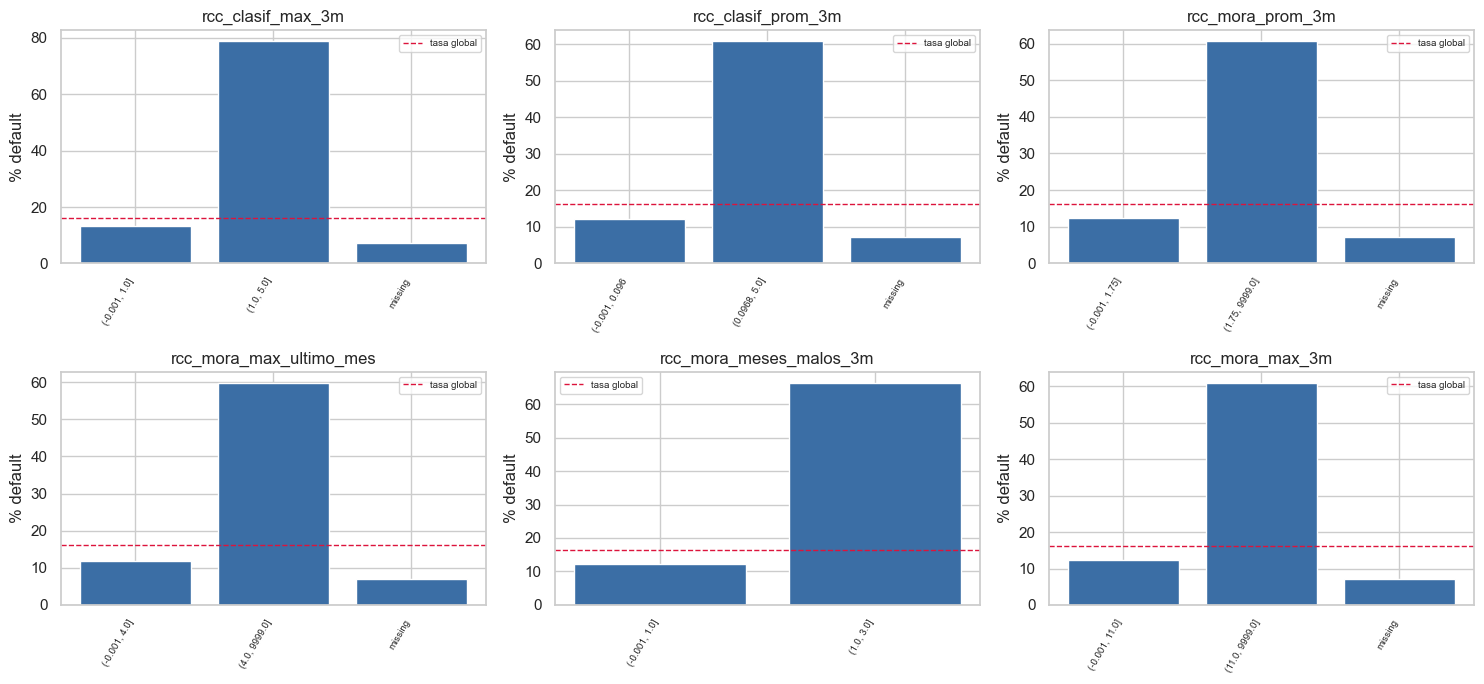

In [9]:
top = uni.variable.head(6).tolist()
idx = X.index.intersection(y.index)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), top):
    eda.default_rate_by_bin(X.loc[idx, c], y.loc[idx], ax=ax)
plt.tight_layout()
plt.show()